In [ ]:
from google.colab import drive
drive.mount('/content/drive')

Mounted at /content/drive


In [ ]:
path = '/content/drive/MyDrive/1_2568_AM260_Grp05/Project/DATAcleaned/Housing_cleaned.csv'

In [ ]:
path2 = '/content/drive/MyDrive/1_2568_AM260_Grp05/Project/DATAcleaned/Housing(log).csv'

In [ ]:
import pandas as pd
# อ่านไฟล์
df = pd.read_csv(path)

In [ ]:
# ขนาดของตารางข้อมูล
print(df.shape)

(545, 14)


In [ ]:
# รายละเอียดของ DataFrame
print(df.info())

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 545 entries, 0 to 544
Data columns (total 14 columns):
 #   Column                           Non-Null Count  Dtype
---  ------                           --------------  -----
 0   price                            545 non-null    int64
 1   area                             545 non-null    int64
 2   bedrooms                         545 non-null    int64
 3   bathrooms                        545 non-null    int64
 4   stories                          545 non-null    int64
 5   mainroad                         545 non-null    int64
 6   guestroom                        545 non-null    int64
 7   basement                         545 non-null    int64
 8   hotwaterheating                  545 non-null    int64
 9   airconditioning                  545 non-null    int64
 10  parking                          545 non-null    int64
 11  prefarea                         545 non-null    int64
 12  furnishingstatus_semi_furnished  545 non-null    i

In [ ]:
# ข้อมูล 5 แถวแรกของตาราง
print(df.head())

      price  area  bedrooms  bathrooms  stories  mainroad  guestroom  \
0  13300000  7420         4          2        3         1          0   
1  12250000  8960         4          4        4         1          0   
2  12250000  9960         3          2        2         1          0   
3  12215000  7500         4          2        2         1          0   
4  11410000  7420         4          1        2         1          1   

   basement  hotwaterheating  airconditioning  parking  prefarea  \
0         0                0                1        2         1   
1         0                0                1        3         0   
2         1                0                0        2         1   
3         1                0                1        3         1   
4         1                0                1        2         0   

   furnishingstatus_semi_furnished  furnishingstatus_unfurnished  
0                                0                             0  
1                       

In [ ]:
print(df.dtypes)

price                              int64
area                               int64
bedrooms                           int64
bathrooms                          int64
stories                            int64
mainroad                           int64
guestroom                          int64
basement                           int64
hotwaterheating                    int64
airconditioning                    int64
parking                            int64
prefarea                           int64
furnishingstatus_semi_furnished    int64
furnishingstatus_unfurnished       int64
dtype: object


**สมมติฐานที่ 1 — ไม่มี Multicollinearity**

In [ ]:
#นำเข้า library ที่ต้องใช้
import pandas as pd
import statsmodels.api as sm
from statsmodels.stats.outliers_influence import variance_inflation_factor

#สร้างตัวแปรอิสระ (X) และตัวแปรตาม (Y)
# เลือกตัวแปรอิสระทั้งหมด ยกเว้น 'price' (ตัวแปรตาม)
X = df[['area', 'bedrooms', 'bathrooms', 'stories', 'mainroad', 'guestroom',
        'basement', 'hotwaterheating', 'airconditioning', 'parking', 'prefarea',
        'furnishingstatus_semi_furnished', 'furnishingstatus_unfurnished']]
Y = df['price']

#เพิ่มค่า constant ให้ X (เพื่อให้มีค่า intercept ในโมเดล)
X = sm.add_constant(X)

#คำนวณค่า VIF
vif_data = pd.DataFrame()
vif_data["Variable"] = X.columns
vif_data["VIF"] = [variance_inflation_factor(X.values, i)
                   for i in range(X.shape[1])]

#แสดงผล
print("VIF Test for Multicollinearity:")
print(vif_data.sort_values(by='VIF', ascending=False))

# **สำคัญ: ต้องสร้างโมเดล (model) ขึ้นมาก่อน เพื่อใช้ในการทดสอบสมมติฐานถัดไป**
model = sm.OLS(Y, X).fit()
print("\nOLS Model Summary created for subsequent tests.")

VIF Test for Multicollinearity:
                           Variable        VIF
0                             const  33.384521
13     furnishingstatus_unfurnished   1.674139
12  furnishingstatus_semi_furnished   1.578233
4                           stories   1.478055
2                          bedrooms   1.369477
1                              area   1.325250
7                          basement   1.323050
3                         bathrooms   1.286621
6                         guestroom   1.212838
10                          parking   1.212837
9                   airconditioning   1.211840
5                          mainroad   1.172728
11                         prefarea   1.149196
8                   hotwaterheating   1.041506

OLS Model Summary created for subsequent tests.


In [ ]:
# แบบเรียง
from statsmodels.stats.outliers_influence import variance_inflation_factor

vif_data = pd.DataFrame()
vif_data["Variable"] = X.columns
vif_data["VIF"] = [variance_inflation_factor(X.values, i) for i in range(X.shape[1])]
print(vif_data)

                           Variable        VIF
0                             const  33.384521
1                              area   1.325250
2                          bedrooms   1.369477
3                         bathrooms   1.286621
4                           stories   1.478055
5                          mainroad   1.172728
6                         guestroom   1.212838
7                          basement   1.323050
8                   hotwaterheating   1.041506
9                   airconditioning   1.211840
10                          parking   1.212837
11                         prefarea   1.149196
12  furnishingstatus_semi_furnished   1.578233
13     furnishingstatus_unfurnished   1.674139


**สมมติฐานที่ 2 — ความเป็นเชิงเส้น (Linearity)**

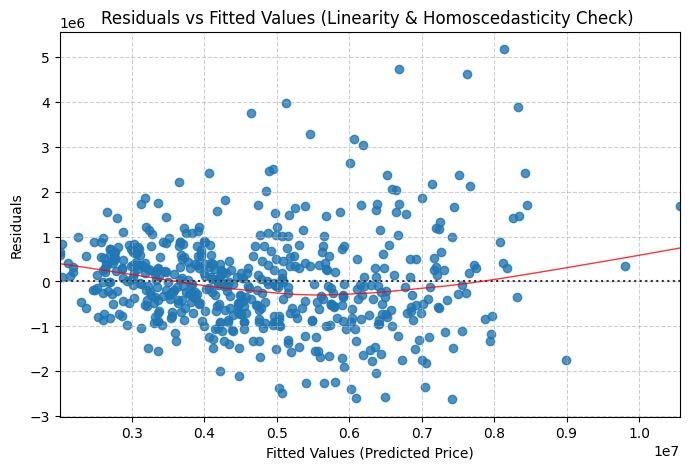

In [ ]:
import matplotlib.pyplot as plt
import seaborn as sns

plt.figure(figsize=(8, 5))
sns.residplot(x=model.fittedvalues, y=model.resid, lowess=True, line_kws={'color': 'red', 'lw': 1, 'alpha': 0.8})
plt.xlabel("Fitted Values (Predicted Price)")
plt.ylabel("Residuals")
plt.title("Residuals vs Fitted Values (Linearity & Homoscedasticity Check) ")
plt.grid(True, linestyle='--', alpha=0.6)
plt.show()

**สมมติฐานที่ 3 — Residuals ต้องมีการกระจายแบบปกติ (Normality)**

Shapiro-Wilk Test: stat=0.954, p=0.000
H0: Residuals มีการกระจายแบบปกติ
หาก p-value < 0.05 ให้ปฏิเสธ H0 (ไม่เป็นปกติ)


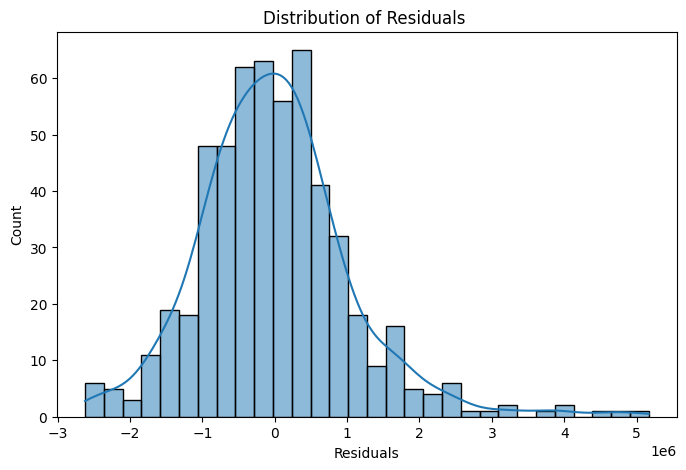

Shapiro-Wilk Test: stat=0.954, p=0.000


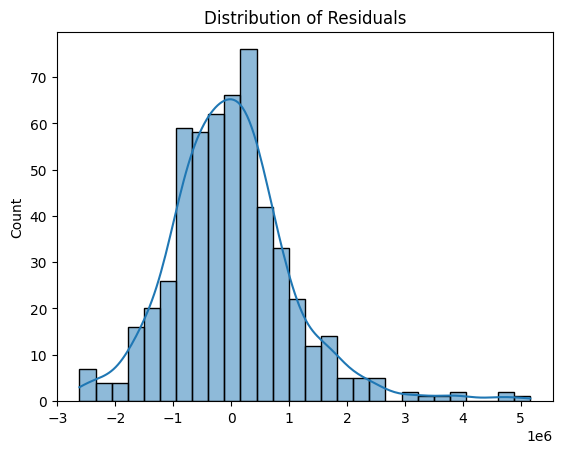

In [ ]:
from scipy.stats import shapiro
from scipy.stats import shapiro
import matplotlib.pyplot as plt
import seaborn as sns

# ทดสอบ Shapiro-Wilk
stat, p = shapiro(model.resid)
print('Shapiro-Wilk Test: stat=%.3f, p=%.3f' % (stat, p))
print('H0: Residuals มีการกระจายแบบปกติ')
print('หาก p-value < 0.05 ให้ปฏิเสธ H0 (ไม่เป็นปกติ)')

# ดูกราฟ Histogram
plt.figure(figsize=(8, 5))
sns.histplot(model.resid, kde=True, bins=30)
plt.title("Distribution of Residuals ")
plt.xlabel("Residuals")
plt.show()
# ทดสอบ Shapiro-Wilk
stat, p = shapiro(model.resid)
print('Shapiro-Wilk Test: stat=%.3f, p=%.3f' % (stat, p))

# ดูกราฟ Histogram
sns.histplot(model.resid, kde=True)
plt.title("Distribution of Residuals")
plt.show()

**สมมติฐานที่ 4 — Homoscedasticity (ความแปรปรวนคงที่ของ residuals)**

In [ ]:
from statsmodels.stats.diagnostic import het_breuschpagan
import numpy as np

# model.model.exog คือตัวแปรอิสระ X (รวม constant)
bp_test = het_breuschpagan(model.resid, model.model.exog)
labels = ['Lagrange multiplier', 'p-value (LM)', 'f-value', 'f p-value']
print("Breusch-Pagan Test for Homoscedasticity:")
print("H0: ความแปรปรวนคงที่ (Homoscedasticity)")
print(dict(zip(labels, bp_test)))
print('หาก p-value < 0.05 ให้ปฏิเสธ H0 (เป็น Heteroscedasticity)')

Breusch-Pagan Test for Homoscedasticity:
H 0: ความแปรปรวนคงที่ (Homoscedasticity)
{'Lagrange multiplier': np.float64(68.41642155741263), 'p-value (LM)': np.float64(1.568581940390958e-09), 'f-value': np.float64(5.8637095505254475), 'f p-value': np.float64(3.493872033548572e-10)}
หาก p-value < 0.05 ให้ปฏิเสธ H0 (เป็น Heteroscedasticity)


**โค้ด Python สำหรับแก้ไขและทดสอบซ้ำ:**

In [ ]:
import pandas as pd
import statsmodels.api as sm
from statsmodels.stats.outliers_influence import variance_inflation_factor

# 2. กำหนดรายการตัวแปรอิสระ
X_cols = ['area', 'bedrooms', 'bathrooms', 'stories', 'mainroad', 'guestroom',
          'basement', 'hotwaterheating', 'airconditioning', 'parking', 'prefarea',
          'furnishingstatus_semi_furnished', 'furnishingstatus_unfurnished']

# 3. สร้าง DataFrame X
X = df[X_cols]

# 4. เพิ่มค่า constant ให้ X (เพื่อให้มีค่า intercept ในโมเดล)
X = sm.add_constant(X)

# 5. คำนวณค่า VIF (ส่วนที่ทำให้เกิด Error ถูกนำมาใส่ต่อจากส่วนที่สร้าง X)
vif_data = pd.DataFrame()
vif_data["Variable"] = X.columns
vif_data["VIF"] = [variance_inflation_factor(X.values, i)
                   for i in range(X.shape[1])]

# 6. แสดงผลลัพธ์
print("VIF Test Results:")
print(vif_data.sort_values(by='VIF', ascending=False).to_string(index=False))

VIF Test Results:
                       Variable       VIF
                          const 33.384521
   furnishingstatus_unfurnished  1.674139
furnishingstatus_semi_furnished  1.578233
                        stories  1.478055
                       bedrooms  1.369477
                           area  1.325250
                       basement  1.323050
                      bathrooms  1.286621
                      guestroom  1.212838
                        parking  1.212837
                airconditioning  1.211840
                       mainroad  1.172728
                       prefarea  1.149196
                hotwaterheating  1.041506


--- OLS Model Re-fitted with log(price) ---

--- Assumption 3 (Re-check): Normality of Residuals (Log Model) ---
Shapiro-Wilk Test (Log Model): stat=0.995, p-value=0.074
H0: Residuals มีการกระจายแบบปกติ
Histogram saved as residuals_histogram_log_model.png

--- Assumption 4 (Re-check): Homoscedasticity (Breusch-Pagan Test) (Log Model) ---
Breusch-Pagan Test (Log Model):
Lagrange multiplier: 29.838
p-value (LM): 0.005
f-value: 2.366
f p-value: 0.004
H0: ความแปรปรวนคงที่ (Homoscedasticity)

--- Assumption 2 (Re-check): Linearity & Homoscedasticity Visual Check (Log Model) ---
Plot saved as residuals_vs_fitted_log_model.png


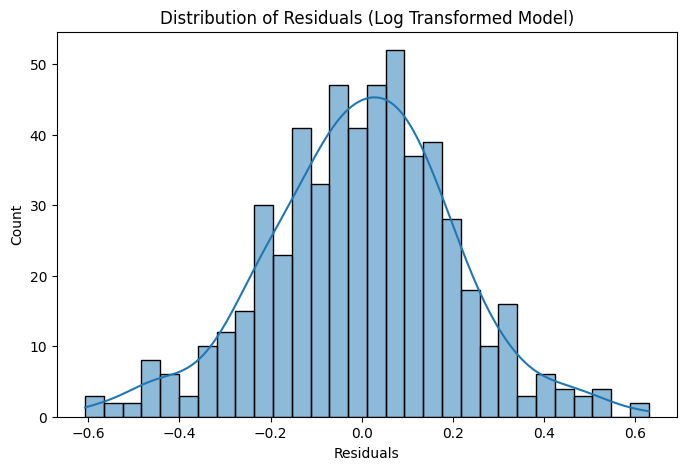

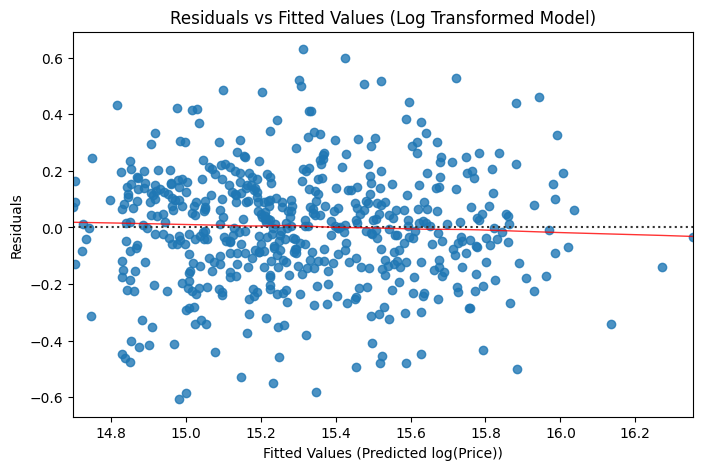

In [ ]:
import pandas as pd
import numpy as np
import statsmodels.api as sm
from scipy.stats import shapiro
from statsmodels.stats.diagnostic import het_breuschpagan
import matplotlib.pyplot as plt
import seaborn as sns

X_cols = ['area', 'bedrooms', 'bathrooms', 'stories', 'mainroad', 'guestroom',
          'basement', 'hotwaterheating', 'airconditioning', 'parking', 'prefarea',
          'furnishingstatus_semi_furnished', 'furnishingstatus_unfurnished']
X = df[X_cols]
X = sm.add_constant(X)
# Y = df['price'] # Original Y

# --- FIX: Log Transformation ---

# 1. Create the new log-transformed dependent variable (Y_log)
df['price_log'] = np.log(df['price'])
Y_log = df['price_log']

# 2. Re-fit the OLS model using the log-transformed price
model_log = sm.OLS(Y_log, X).fit()

print("--- OLS Model Re-fitted with log(price) ---")

# 3. Re-check Normality (Shapiro-Wilk Test and Histogram)
print("\n--- Assumption 3 (Re-check): Normality of Residuals (Log Model) ---")
stat, p = shapiro(model_log.resid)
print(f'Shapiro-Wilk Test (Log Model): stat={stat:.3f}, p-value={p:.3f}')
print('H0: Residuals มีการกระจายแบบปกติ')

# Histogram
plt.figure(figsize=(8, 5))
sns.histplot(model_log.resid, kde=True, bins=30)
plt.title("Distribution of Residuals (Log Transformed Model)")
plt.xlabel("Residuals")
plt.savefig("residuals_histogram_log_model.png")
print("Histogram saved as residuals_histogram_log_model.png")


# 4. Re-check Homoscedasticity (Breusch-Pagan Test)
print("\n--- Assumption 4 (Re-check): Homoscedasticity (Breusch-Pagan Test) (Log Model) ---")
bp_test = het_breuschpagan(model_log.resid, model_log.model.exog)
labels = ['Lagrange multiplier', 'p-value (LM)', 'f-value', 'f p-value']
results = dict(zip(labels, bp_test))

print("Breusch-Pagan Test (Log Model):")
for label, value in results.items():
    print(f"{label}: {value:.3f}")
print('H0: ความแปรปรวนคงที่ (Homoscedasticity)')


# 5. Re-check Linearity (Residuals vs Fitted Plot)
print("\n--- Assumption 2 (Re-check): Linearity & Homoscedasticity Visual Check (Log Model) ---")
plt.figure(figsize=(8, 5))
sns.residplot(x=model_log.fittedvalues, y=model_log.resid, lowess=True, line_kws={'color': 'red', 'lw': 1, 'alpha': 0.8})
plt.xlabel("Fitted Values (Predicted log(Price))")
plt.ylabel("Residuals")
plt.title("Residuals vs Fitted Values (Log Transformed Model)")
plt.savefig("residuals_vs_fitted_log_model.png")
print("Plot saved as residuals_vs_fitted_log_model.png")